# Laboratorio 11 · Búsqueda eficiente de rostros con pgvector
**Alumno:** Jose Ernesto Guerrero Cueva  
**Curso:** Base de Datos II · **Estado:** preparado para ejecutar; sin resultados inventados.

## Qué debes completar tú
1. Instalar Docker Desktop y Miniconda/Anaconda si aún no los tienes. Abrir Docker Desktop.
2. Ejecutar los comandos de P0 en Anaconda Prompt y abrir este notebook con el kernel **Python (lab11)**.
3. Descargar y descomprimir LFW con la estructura `lfw/Nombre_Persona/imagen.jpg`.
4. Editar **solo la celda CONFIGURACIÓN**: ruta de LFW y ruta de tu propia foto. La foto debe contener un solo rostro, de frente y con buena luz.
5. Ejecutar las celdas en orden. La extracción y la construcción de índices pueden tardar bastante.
6. En P4.2 cambiar `EJECUTAR_BENCHMARK_COMPLETO` a `True` y ejecutar esa celda para completar el rendimiento.
7. Completar las celdas **TU RESPUESTA** con lo que realmente obtengas y tomar las capturas señaladas.
8. Guardar el `.ipynb` con sus salidas y adjuntarlo a tu informe.

**Consultas SQL:** el notebook las ejecuta automáticamente. No necesitas repetirlas en pgAdmin.
La sección final genera `resultados/consultas_ejecutables.sql`, con un vector de consulta real de LFW,
para ejecutarlas manualmente en pgAdmin o DBeaver si quieres capturas adicionales.
El archivo SQL separado que acompaña este notebook es la misma plantilla, antes de rellenar ese vector.

**Datos de tu foto:** el embedding personal se mantiene en memoria, no se inserta en PostgreSQL
ni se guarda en archivos. No se exporta tu foto al informe. Al final hay una celda para limpiar la variable.
Usa exclusivamente tu propia foto, como exige el laboratorio.

**Importante:** usa una instalación local de Jupyter. En Colab, `localhost` sería la máquina de Colab,
no tu computadora con Docker. Este notebook no está preparado para esa conexión remota.


## P0 · Preparación fuera del notebook
En **Anaconda Prompt**, ejecutar una vez:
```bat
conda create -n lab11 python=3.12 -y
conda activate lab11
conda install -c conda-forge dlib pandas matplotlib jupyter ipykernel -y
python -m pip install face_recognition psycopg2-binary pgvector
python -m ipykernel install --user --name lab11 --display-name "Python (lab11)"
```
Con Docker Desktop abierto, ejecutar en la terminal (una sola línea):
```bat
docker run -d --name pgvector-lab11 -e POSTGRES_PASSWORD=123456 -p 127.0.0.1:5433:5432 -v pgvector_lab11_data:/var/lib/postgresql/data pgvector/pgvector:pg16
```
En sesiones posteriores, el contenedor ya existe: usar `docker start pgvector-lab11`.
Comprobar disponibilidad con `docker exec pgvector-lab11 pg_isready -U postgres`.
Luego, desde la carpeta donde guardaste el notebook:
```bat
conda activate lab11
jupyter notebook
```
Selecciona el kernel **Python (lab11)**. PostgreSQL conserva los datos en el volumen de Docker.
La contraseña anterior es la del entorno local del laboratorio.


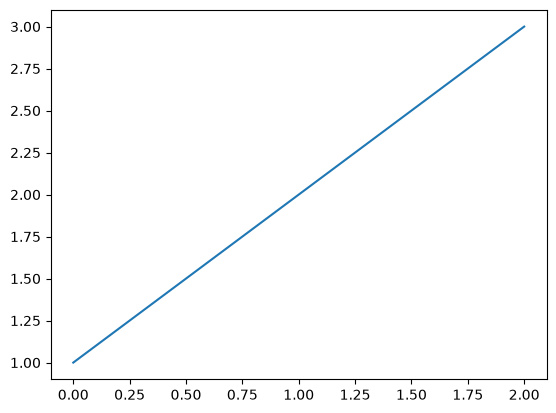

In [3]:
%matplotlib inline

import matplotlib.pyplot as plt

plt.plot([1, 2, 3])
plt.show()

In [4]:
from pathlib import Path
from contextlib import contextmanager
from time import perf_counter
import os, json, math, statistics, platform, sys, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import face_recognition
import psycopg2
from psycopg2.extras import execute_values
from pgvector.psycopg2 import register_vector
from IPython.display import display, Markdown

plt.rcParams.update({'figure.figsize': (9, 5), 'axes.grid': True})
pd.set_option('display.max_columns', 20)
print('Python:', sys.version.split()[0], '| Sistema:', platform.platform())


C:\Users\juanl\anaconda3\envs\lab11\Lib\site-packages\face_recognition_models\__init__.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


Python: 3.12.16 | Sistema: Windows-11-10.0.26200-SP0


### CONFIGURACIÓN
`DATASET_PATH` debe apuntar a la carpeta que contiene las carpetas de personas.
No a una carpeta que contiene solamente el archivo comprimido.
Procesamos todas las imágenes: se necesitan **12 100 embeddings válidos como mínimo**
para reservar 100 consultas y medir hasta 12 000 registros.


In [5]:
DATASET_PATH = Path("lfw_funneled")
MI_FOTO_PATH = Path("mi_foto.jpg")

DB_CONFIG = dict(host='localhost', port=5433, user='postgres', password='123456', dbname='postgres')
N_PROCESAR = None  # None = todas; para la entrega no reducir a una muestra pequeña
N_TRABAJO = 12000
N_CONSULTAS = 100
K = 10
SEMILLA = 42
LISTS_P3 = 100  # mantenemos el ejemplo del enunciado; P4.2 usa round(sqrt(N))
REPETICIONES = 10  # 1 calentamiento adicional + 10 mediciones conservadas

OUT = Path('resultados')
CACHE = Path('cache_lab11')
OUT.mkdir(exist_ok=True)
CACHE.mkdir(exist_ok=True)
if not DATASET_PATH.is_dir():
    raise FileNotFoundError('TÚ: cambia DATASET_PATH a tu carpeta LFW descomprimida.')
coleccion = pd.DataFrame([
    {'person': p.parent.name, 'path': str(p.resolve())}
    for p in sorted(DATASET_PATH.rglob('*.jpg'))
])
if coleccion.empty:
    raise ValueError('No se encontraron JPG. Revisa la ruta y la estructura de LFW.')
print(f'{len(coleccion):,} fotos | {coleccion.person.nunique():,} personas')
display(coleccion.head())


13,233 fotos | 5,749 personas


,person,path
0,Aaron_Eckhart,C:\Users\juanl\jose_utec\bd2\lab11\lfw_funnele...
1,Aaron_Guiel,C:\Users\juanl\jose_utec\bd2\lab11\lfw_funnele...
2,Aaron_Patterson,C:\Users\juanl\jose_utec\bd2\lab11\lfw_funnele...
3,Aaron_Peirsol,C:\Users\juanl\jose_utec\bd2\lab11\lfw_funnele...
4,Aaron_Peirsol,C:\Users\juanl\jose_utec\bd2\lab11\lfw_funnele...


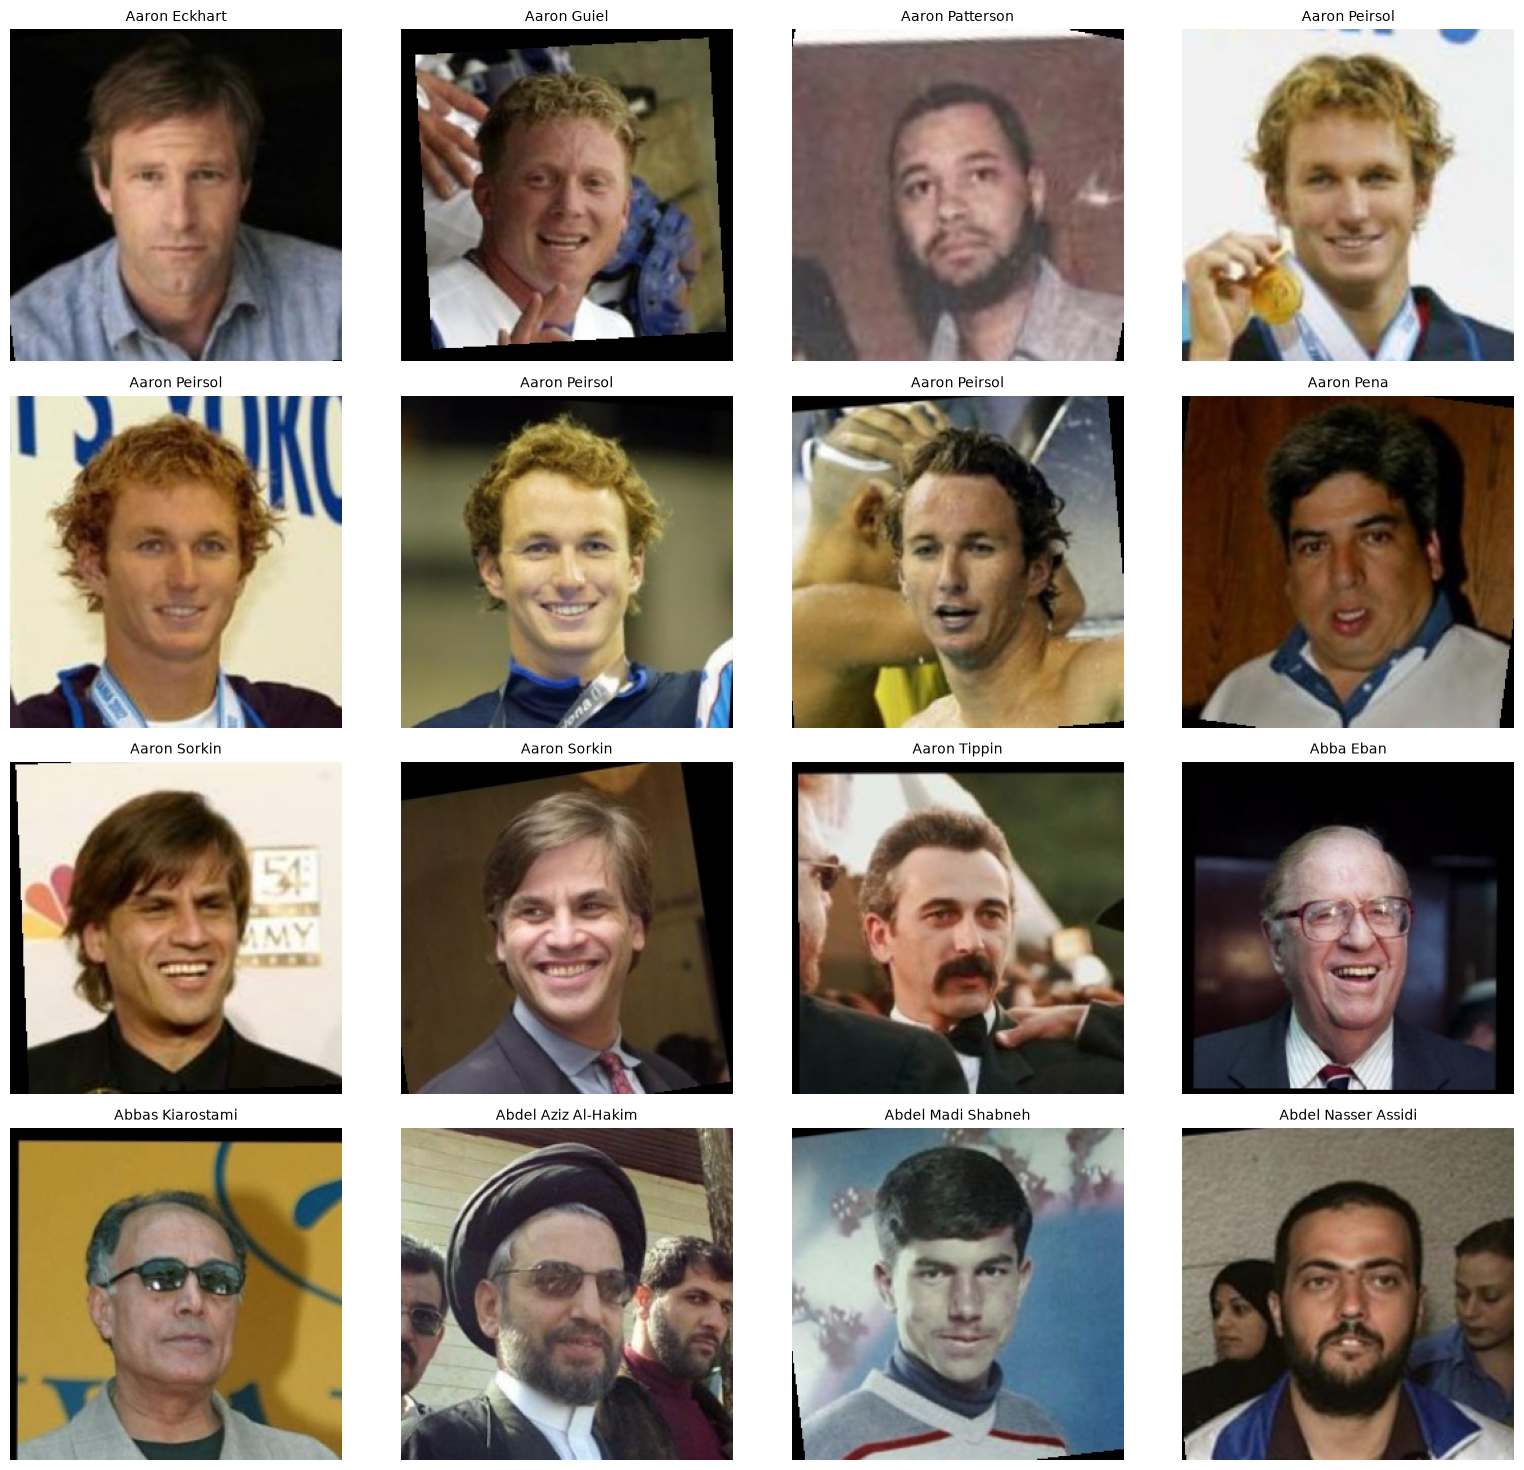

In [6]:
def mostrarFotos(df, posiciones, columnas=4):
    posiciones = list(posiciones)
    if not posiciones:
        return
    filas = math.ceil(len(posiciones) / columnas)
    fig, axes = plt.subplots(filas, columnas, figsize=(4 * columnas, 3.7 * filas), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, idx in zip(axes.flat, posiciones):
        row = df.iloc[idx]
        ax.imshow(plt.imread(row['path']))
        titulo = row['person'].replace('_', ' ')
        if 'dist' in df.columns:
            titulo += f"\ndistancia = {row['dist']:.4f}"
        ax.set_title(titulo, fontsize=10)
    fig.tight_layout()
    plt.show()

mostrarFotos(coleccion, range(min(16, len(coleccion))))


## P1 · Generar y almacenar vectores (4 pts)
La función mantiene la correspondencia persona–ruta–vector y usa el primer rostro detectado,
tal como indica el enunciado. Descarta imágenes sin rostro o con error y registra el motivo.
Guarda un checkpoint cada 100 imágenes para poder reanudar. Si cambias el contenido de LFW
o las librerías de extracción, borra `cache_lab11/embeddings.npz` para recalcular.
El caché contiene solo imágenes del dataset, nunca tu foto personal.


In [ ]:
def generate_face_embeddings(coleccion, n=None):
    lote = coleccion if n is None else coleccion.iloc[:n]
    archivo = CACHE / 'embeddings.npz'
    exitos, fallos = {}, {}
    if archivo.exists():
        with np.load(archivo, allow_pickle=False) as z:
            if str(z['dataset_root'].item()) != str(DATASET_PATH.resolve()):
                raise ValueError('El caché es de otra ruta. Bórralo o restaura DATASET_PATH.')
            for person, path, embedding in zip(z['persons'], z['paths'], z['embeddings']):
                exitos[str(path)] = (str(person), embedding)
            fallos = dict(zip(z['failed_paths'].tolist(), z['failed_reasons'].tolist()))

    def guardar():
        paths = list(exitos)
        vectors = np.stack([exitos[p][1] for p in paths]) if paths else np.empty((0, 128), dtype=np.float32)
        temporal = CACHE / 'embeddings.tmp.npz'
        np.savez_compressed(temporal, dataset_root=str(DATASET_PATH.resolve()),
                            persons=np.array([exitos[p][0] for p in paths], dtype=str),
                            paths=np.array(paths, dtype=str), embeddings=vectors,
                            failed_paths=np.array(list(fallos), dtype=str),
                            failed_reasons=np.array(list(fallos.values()), dtype=str))
        temporal.replace(archivo)

    pendientes = 0
    try:
        for i, row in enumerate(lote.itertuples(index=False), 1):
            if row.path in exitos or row.path in fallos:
                continue
            try:
                img = face_recognition.load_image_file(row.path)
                encodings = face_recognition.face_encodings(img)
                if not encodings:
                    fallos[row.path] = 'sin rostro'
                else:
                    emb = np.asarray(encodings[0], dtype=np.float32)
                    if emb.shape != (128,) or not np.isfinite(emb).all():
                        raise ValueError('Embedding inválido')
                    exitos[row.path] = (row.person, emb)
            except Exception as e:
                fallos[row.path] = f'{type(e).__name__}: {e}'
            pendientes += 1
            if pendientes % 100 == 0:
                guardar()
                print(f'Procesadas {i:,}/{len(lote):,}; válidas acumuladas: {len(exitos):,}', flush=True)
    finally:
        guardar()  # incluso si interrumpes la celda

    rows = [{'person': row.person, 'path': row.path, 'embedding': exitos[row.path][1]}
            for row in lote.itertuples(index=False) if row.path in exitos]
    pd.DataFrame([{'path': p, 'motivo': reason} for p, reason in fallos.items()]).to_csv(
        OUT / 'imagenes_descartadas.csv', index=False)
    return pd.DataFrame(rows, columns=['person', 'path', 'embedding'])

embeddings = generate_face_embeddings(coleccion, N_PROCESAR)
print(f'Embeddings válidos: {len(embeddings):,}')
if len(embeddings) < N_TRABAJO + N_CONSULTAS:
    raise ValueError(f'Se necesitan {N_TRABAJO + N_CONSULTAS:,} embeddings válidos. '
                     'Procesa todo LFW y revisa los descartes. No inventes los tamaños faltantes.')


Procesadas 100/13,233; válidas acumuladas: 99
Procesadas 200/13,233; válidas acumuladas: 199
Procesadas 300/13,233; válidas acumuladas: 299
Procesadas 400/13,233; válidas acumuladas: 399
Procesadas 500/13,233; válidas acumuladas: 499
Procesadas 600/13,233; válidas acumuladas: 599
Procesadas 700/13,233; válidas acumuladas: 698
Procesadas 800/13,233; válidas acumuladas: 797
Procesadas 900/13,233; válidas acumuladas: 895
Procesadas 1,000/13,233; válidas acumuladas: 993
Procesadas 1,100/13,233; válidas acumuladas: 1,093
Procesadas 1,200/13,233; válidas acumuladas: 1,193
Procesadas 1,300/13,233; válidas acumuladas: 1,293
Procesadas 1,400/13,233; válidas acumuladas: 1,393
Procesadas 1,500/13,233; válidas acumuladas: 1,492
Procesadas 1,600/13,233; válidas acumuladas: 1,590
Procesadas 1,700/13,233; válidas acumuladas: 1,690
Procesadas 1,800/13,233; válidas acumuladas: 1,790
Procesadas 1,900/13,233; válidas acumuladas: 1,890
Procesadas 2,000/13,233; válidas acumuladas: 1,989
Procesadas 2,100/13

In [ ]:
def separar_consultas(df, cantidad=100, semilla=42):
    # Reservamos una foto de cada una de 100 personas diferentes con >= 2 fotos válidas.
    # Así siempre queda al menos una foto de cada persona en la colección no reservada.
    counts = df.groupby('person').size()
    elegibles = sorted(counts[counts >= 2].index)
    if len(elegibles) < cantidad:
        raise ValueError('No hay suficientes personas con >= 2 fotos válidas.')
    rng = np.random.default_rng(semilla)
    personas = rng.choice(elegibles, size=cantidad, replace=False)
    indices = [int(rng.choice(df.index[df.person.eq(persona)].to_numpy())) for persona in personas]
    consultas = df.loc[indices].reset_index(drop=True)
    base = df.drop(index=indices).reset_index(drop=True)
    assert set(consultas.path).isdisjoint(base.path)
    assert set(consultas.person).issubset(set(base.person))
    return base, consultas

base_completa, consultas = separar_consultas(embeddings, N_CONSULTAS, SEMILLA)
base = base_completa.iloc[:N_TRABAJO].copy().reset_index(drop=True)
consultas[['person', 'path']].to_csv(OUT / 'consultas_reservadas.csv', index=False)
base[['person', 'path']].to_csv(OUT / 'coleccion_insertada.csv', index=False)
print('Colección:', len(base), '| Consultas reservadas:', len(consultas))
print('Personas de consulta con foto en las primeras 12000:', consultas.person.isin(base.person).sum())
print('El recall mide vecinos geométricos exactos, no aciertos de identidad.')


### Conectar y cargar la tabla
Todo el trabajo utiliza el esquema **`lab11`**. La recarga reemplaza exclusivamente
`lab11.face_embeddings`; usa este esquema solo para el laboratorio.
No inserta las 100 fotos reservadas. Al ejecutar otra vez se recarga la tabla sin duplicar filas.


In [ ]:
conn = psycopg2.connect(**DB_CONFIG)
conn.autocommit = True
cur = conn.cursor()
cur.execute('CREATE EXTENSION IF NOT EXISTS vector')
register_vector(conn)
cur.execute('CREATE SCHEMA IF NOT EXISTS lab11')
cur.execute("""
CREATE TABLE IF NOT EXISTS lab11.face_embeddings (
    id SERIAL PRIMARY KEY,
    name TEXT NOT NULL,
    path TEXT UNIQUE NOT NULL,
    embedding VECTOR(128) NOT NULL
)
""")
cur.execute("SELECT extversion FROM pg_extension WHERE extname = 'vector'")
version_vector = cur.fetchone()[0]
print('pgvector:', version_vector)
cur.execute('SELECT version()')
version_postgres = cur.fetchone()[0]
# Controlar JIT para evitar que penalice artificialmente un Seq Scan desaconsejado.
cur.execute('SET jit = off')
cur.execute('SET max_parallel_workers_per_gather = 0')
# Si la versión soporta búsqueda iterativa, apagarla para comparar los parámetros pedidos.
for nombre in ('hnsw.iterative_scan', 'ivfflat.iterative_scan'):
    cur.execute('SELECT current_setting(%s, true)', (nombre,))
    if cur.fetchone()[0] is not None:
        cur.execute('SELECT set_config(%s, %s, false)', (nombre, 'off'))

def drop_indices():
    cur.execute('DROP INDEX IF EXISTS lab11.face_ivf')
    cur.execute('DROP INDEX IF EXISTS lab11.face_hnsw')

def cargar_base(df):
    if len(df) < K:
        raise ValueError('La tabla debe contener al menos k filas.')
    drop_indices()
    # Una transacción evita dejar la tabla a medio cargar si ocurre un error.
    with conn:
        cur.execute('TRUNCATE lab11.face_embeddings RESTART IDENTITY')
        registros = [(r.person, r.path, np.asarray(r.embedding, dtype=np.float32))
                     for r in df.itertuples(index=False)]
        execute_values(cur, 'INSERT INTO lab11.face_embeddings (name, path, embedding) VALUES %s',
                       registros, page_size=500)
    cur.execute('ANALYZE lab11.face_embeddings')
    cur.execute('SELECT COUNT(*) FROM lab11.face_embeddings')
    assert cur.fetchone()[0] == len(df)

cargar_base(base)
metadatos = {'python': sys.version, 'postgres': version_postgres, 'pgvector': version_vector,
             'semilla': SEMILLA, 'N': len(base), 'consultas': len(consultas),
             'jit': 'off', 'max_parallel_workers_per_gather': 0,
             'nota': 'Latencias en caliente; orden de imágenes lexicográfico; consultas fijas.'}
metadatos['librerias'] = {p: importlib.metadata.version(p) for p in
                         ['numpy', 'pandas', 'matplotlib', 'face-recognition', 'psycopg2-binary', 'pgvector']}
(OUT / 'entorno.json').write_text(json.dumps(metadatos, indent=2, ensure_ascii=False), encoding='utf-8')
print('Tabla cargada. Las consultas reservadas NO se insertaron.')


## Funciones compartidas: búsqueda, parámetros y planes
Los parámetros temporales se restauran incluso si falla una consulta. En búsqueda exacta
se desactivan Index Scan, Index Only Scan y Bitmap Scan. Para ANN se desaconseja Seq Scan;
esto **no garantiza** un índice: se comprueba el plan real.
Los operadores se eligen desde una lista cerrada, no desde texto SQL arbitrario.


In [ ]:
@contextmanager
def ajustes(**valores):
    anteriores = {}
    try:
        for nombre, valor in valores.items():
            cur.execute('SELECT current_setting(%s)', (nombre,))
            anteriores[nombre] = cur.fetchone()[0]
            cur.execute('SELECT set_config(%s, %s, false)', (nombre, str(valor)))
        yield
    finally:
        for nombre, valor in anteriores.items():
            cur.execute('SELECT set_config(%s, %s, false)', (nombre, valor))

EXACTO = dict(enable_seqscan='on', enable_indexscan='off',
              enable_indexonlyscan='off', enable_bitmapscan='off')
ANN = dict(enable_seqscan='off', enable_indexscan='on', enable_indexonlyscan='on')

def sql_knn(op='<->', detalles=False):
    if op not in ('<->', '<=>'):
        raise ValueError('Operador no permitido')
    campos = f'id, name, path, embedding {op} %s AS dist' if detalles else 'id'
    return f'SELECT {campos} FROM lab11.face_embeddings ORDER BY embedding {op} %s LIMIT %s'

def parametros_knn(q, k=10, detalles=False):
    q = np.asarray(q, dtype=np.float32)
    if q.shape != (128,) or not np.isfinite(q).all():
        raise ValueError('Se requiere un vector finito de 128 dimensiones')
    return (q, q, int(k)) if detalles else (q, int(k))

def knn(q, k=10, op='<->', detalles=False):
    cur.execute(sql_knn(op, detalles), parametros_knn(q, k, detalles))
    rows = cur.fetchall()
    return pd.DataFrame(rows, columns=['id', 'name', 'path', 'dist']) if detalles else [r[0] for r in rows]

def knn_lineal(q, k=10, op='<->', detalles=False):
    with ajustes(**EXACTO):
        return knn(q, k, op, detalles)

def recall_at_k(exactos, aproximados):
    if not exactos:
        raise ValueError('Referencia exacta vacía')
    return len(set(exactos) & set(aproximados)) / len(exactos)

def mediana_cliente(funcion, repeticiones=REPETICIONES):
    funcion()  # calentamiento descartado
    tiempos = []
    for _ in range(repeticiones):
        t0 = perf_counter()
        funcion()
        tiempos.append((perf_counter() - t0) * 1000)
    return float(np.median(tiempos))

def nodos_plan(nodo):
    yield nodo
    for hijo in nodo.get('Plans', []):
        yield from nodos_plan(hijo)

def plan_json(q, k=10):
    cur.execute('EXPLAIN (ANALYZE, BUFFERS, FORMAT JSON) ' + sql_knn(), parametros_knn(q, k))
    doc = cur.fetchone()[0]
    if isinstance(doc, str):
        doc = json.loads(doc)
    return doc[0]

def resumen_plan(doc):
    nodos = list(nodos_plan(doc['Plan']))
    indices = sorted({n['Index Name'] for n in nodos if 'Index Name' in n})
    tipos = sorted({n['Node Type'] for n in nodos})
    return ', '.join(indices) if indices else 'SIN ÍNDICE: ' + ', '.join(tipos)

def guardar_plan(q, etiqueta):
    # El plan de texto se muestra para que puedas capturarlo desde el notebook.
    cur.execute('EXPLAIN (ANALYZE, BUFFERS) ' + sql_knn(), parametros_knn(q, K))
    texto = '\n'.join(r[0] for r in cur.fetchall())
    (OUT / f'{etiqueta}.txt').write_text(texto, encoding='utf-8')
    doc = plan_json(q, K)
    (OUT / f'{etiqueta}.json').write_text(json.dumps(doc, indent=2), encoding='utf-8')
    print(etiqueta, '|', resumen_plan(doc))
    print(texto)
    return doc

def crear_indice(tipo, lists=100):
    drop_indices()  # SIEMPRE un solo índice ANN
    t0 = perf_counter()
    if tipo == 'IVFFlat':
        lists = int(lists)
        if lists < 1:
            raise ValueError('lists debe ser positivo')
        cur.execute(f'CREATE INDEX face_ivf ON lab11.face_embeddings USING ivfflat '
                    f'(embedding vector_l2_ops) WITH (lists = {lists})')
        nombre = 'face_ivf'
    elif tipo == 'HNSW':
        cur.execute('CREATE INDEX face_hnsw ON lab11.face_embeddings USING hnsw '
                    '(embedding vector_l2_ops) WITH (m = 16, ef_construction = 64)')
        nombre = 'face_hnsw'
    else:
        raise ValueError('Índice desconocido')
    build_ms = (perf_counter() - t0) * 1000
    cur.execute('ANALYZE lab11.face_embeddings')
    cur.execute('SELECT pg_relation_size(%s::regclass)', ('lab11.' + nombre,))
    return {'indice': tipo, 'construccion_ms': build_ms, 'tamano_MiB': cur.fetchone()[0] / 2**20}

def parametro_indice(tipo, valor):
    return {'ivfflat.probes' if tipo == 'IVFFlat' else 'hnsw.ef_search': int(valor)}

def parametros_a_probar(tipo, lists):
    if tipo == 'IVFFlat':
        return sorted({min(int(lists), p) for p in (1, 5, 10, 20, int(lists))})
    return [10, 40, 100, 200]

q = consultas.iloc[0].embedding  # foto LFW externa a la tabla; NO es tu foto


## P2.a · kNN lineal: euclidiana y coseno (3 pts, junto con P2.b)
Latencia cliente = consulta + comunicación + recuperación del resultado; no es lo mismo
que `Execution Time` de PostgreSQL. Aquí usamos la mediana de 10 ejecuciones tras calentar.


In [ ]:
drop_indices()
l2 = knn_lineal(q, K, '<->', detalles=True)
cos = knn_lineal(q, K, '<=>', detalles=True)
# Configurar el plan fuera de la medición: cronometrar solo la consulta y su resultado.
with ajustes(**EXACTO):
    tabla_p2 = pd.DataFrame([
        {'distancia': 'euclidiana', 'latencia_mediana_ms': mediana_cliente(lambda: knn(q, K, '<->'))},
        {'distancia': 'coseno', 'latencia_mediana_ms': mediana_cliente(lambda: knn(q, K, '<=>'))}
    ])
display(tabla_p2)
display(l2)
display(cos)
print('Mismo conjunto:', set(l2.id) == set(cos.id))
print('Mismo orden:', l2.id.tolist() == cos.id.tolist())
print('Vecinos comunes:', len(set(l2.id) & set(cos.id)), '/', K)
normas = np.linalg.norm(np.stack(base.embedding), axis=1)
print('Normas de los vectores: min / media / max =', normas.min(), normas.mean(), normas.max())
tabla_p2.to_csv(OUT / 'P2_tiempos.csv', index=False)
l2.to_csv(OUT / 'P2_vecinos_l2.csv', index=False)
cos.to_csv(OUT / 'P2_vecinos_coseno.csv', index=False)
with ajustes(**EXACTO):
    guardar_plan(q, 'P2_plan_lineal')


**TU RESPUESTA P2.a:**
- Medianas L2 y coseno: **[completar]** ms.
- Coinciden el conjunto y el orden: **[completar con la salida]**.
- Explicación: L2 considera diferencias de magnitud y dirección; coseno compara dirección.
  Si ambos vectores tienen norma 1, `L2² = 2 × distancia_coseno` y el orden coincide.
  Aquí no normalizamos los embeddings; observa sus normas antes de explicar tu resultado.

📸 **TÚ:** captura la salida de `P2_plan_lineal`, donde debe verse `Seq Scan`.


## P2.b · Tu doble famoso — TÚ: foto propia
El top se agrupa por persona entre candidatos cercanos, como en el enunciado. Se amplía
la cantidad de candidatos si inicialmente no aparecen cinco personas distintas.
Se muestra la foto de menor distancia de cada persona seleccionada.
El conteo `fotos` corresponde a las fotos de esa persona **en el conjunto candidato**.


In [ ]:
def famoso_parecido(q, candidatos=50, top=5):
    cur.execute('SELECT COUNT(*), COUNT(DISTINCT name) FROM lab11.face_embeddings')
    total, personas = cur.fetchone()
    if personas < top:
        raise ValueError('La tabla no tiene suficientes personas distintas.')
    limite = min(max(candidatos, top), total)
    while True:
        cercanos = knn(q, limite, '<->', detalles=True)
        if cercanos.empty:
            raise RuntimeError('La búsqueda no devolvió candidatos.')
        cercanos = cercanos.sort_values(['dist', 'id'])
        conteos = cercanos.groupby('name').size()
        mejores = cercanos.drop_duplicates('name').head(top).copy()
        mejores['fotos'] = mejores.name.map(conteos)
        if len(mejores) >= top:
            mejores.attrs['candidatos_solicitados'] = limite
            mejores.attrs['candidatos_devueltos'] = len(cercanos)
            return mejores.reset_index(drop=True)
        if limite >= total:
            raise RuntimeError('ANN no devolvió cinco personas. Aumenta probes o ef_search y repite.')
        limite = min(total, limite * 2)

def mostrar_dobles(df, titulo):
    vis = df.rename(columns={'name': 'person'})
    print(titulo, '| candidatos:', df.attrs)
    display(df[['name', 'dist', 'fotos', 'path']])
    mostrarFotos(vis, range(len(vis)), columnas=5)

mi_embedding = None
dobles_lineal = None
if not MI_FOTO_PATH.is_file():
    print('PENDIENTE TÚ: corrige MI_FOTO_PATH y vuelve a ejecutar esta celda y P3.')
else:
    mi_imagen = face_recognition.load_image_file(str(MI_FOTO_PATH))
    mis_encodings = face_recognition.face_encodings(mi_imagen)
    if len(mis_encodings) != 1:
        raise ValueError(f'Se detectaron {len(mis_encodings)} rostros. Usa una foto con un solo rostro.')
    mi_embedding = np.asarray(mis_encodings[0], dtype=np.float32)
    # Tu foto se muestra localmente. Puedes borrar esta salida antes de compartir el notebook.
    plt.figure(figsize=(3, 3))
    plt.imshow(mi_imagen)
    plt.axis('off')
    plt.title('Mi foto — solo para revisión local')
    plt.show()
    with ajustes(**EXACTO):
        dobles_lineal = famoso_parecido(mi_embedding)
    mostrar_dobles(dobles_lineal, 'Búsqueda lineal')
    dobles_lineal.to_csv(OUT / 'P2_dobles_lineal.csv', index=False)
    del mis_encodings, mi_imagen


**TU RESPUESTA P2.b:**
- Mi famoso más cercano: **[nombre]**, distancia L2 **[valor]**.
- Cinco personas distintas obtenidas: **[completar]**.
- Respecto de la referencia 0,6 del enunciado: **[comparar e interpretar]**.
  Ese umbral es una heurística del modelo; una distancia baja por sí sola no prueba identidad.
  Explica el resultado como parecido facial, no como confirmación de que eres esa persona.

Tu foto no es obligatoria en el informe. Si compartes el notebook, puedes borrar únicamente
la salida que muestra tu foto; conserva las tablas y fotos de los cinco resultados del dataset.


## P3 · IVFFlat y HNSW (7 pts)
Se crea un índice a la vez. Ambos usan `vector_l2_ops`, por lo que las búsquedas usan `<->`.
Con `<=>` necesitaríamos `vector_cosine_ops`. Se guardan planes de la consulta reservada.
La búsqueda personal se compara por sus resultados; no se exporta su plan porque podría
contener el vector de tu rostro como literal SQL.


In [ ]:
construcciones = []
dobles_indices = {}
for tipo, valor in [('IVFFlat', 10), ('HNSW', 100)]:
    construcciones.append(crear_indice(tipo, LISTS_P3))
    cfg = {**ANN, **parametro_indice(tipo, valor)}
    esperado = 'face_ivf' if tipo == 'IVFFlat' else 'face_hnsw'
    with ajustes(**cfg):
        plan = guardar_plan(q, f'P3_plan_{tipo}')
        if esperado not in resumen_plan(plan):
            raise RuntimeError('No se usó el índice esperado. Revisa el plan antes de continuar.')
        print('Mediana cliente (ms):', mediana_cliente(lambda: knn(q, K)))
        if mi_embedding is not None:
            resultados = famoso_parecido(mi_embedding)
            dobles_indices[tipo] = resultados
            mostrar_dobles(resultados, tipo)
            resultados.to_csv(OUT / f'P3_dobles_{tipo}.csv', index=False)
        else:
            print('PENDIENTE: completar tu foto en P2.b y volver a ejecutar P3.')

tabla_construcciones = pd.DataFrame(construcciones)
display(tabla_construcciones)
tabla_construcciones.to_csv(OUT / 'P3_construccion_indices.csv', index=False)
if dobles_lineal is not None:
    comparacion_dobles = pd.DataFrame([
        {'metodo': tipo, 'mismo_conjunto_de_5': set(df.name) == set(dobles_lineal.name),
         'mismo_orden': df.name.tolist() == dobles_lineal.name.tolist(),
         'nombres_comunes': len(set(df.name) & set(dobles_lineal.name))}
        for tipo, df in dobles_indices.items()
    ])
    display(comparacion_dobles)
    comparacion_dobles.to_csv(OUT / 'P3_comparacion_dobles.csv', index=False)


**TU RESPUESTA P3:**
- Plan IVFFlat: **[índice que aparece y Execution Time]**.
- Plan HNSW: **[índice que aparece y Execution Time]**.
- Comparación de mis cinco famosos contra la búsqueda lineal: **[completar]**.
- Tiempos de construcción y tamaños: **[completar]**.

📸 **TÚ:** captura los planes donde se ve `Index Scan using face_ivf` y
`Index Scan using face_hnsw`, sus tiempos y los resultados de tus dobles famosos.
**Tamaño en disco** se usa como indicador de almacenamiento; no es una medición de RAM.


## P4.1 · Recall@10 y latencia (3 pts)
Para cada una de las 100 consultas externas a la tabla obtenemos el top 10 exacto.
Luego ejecutamos los parámetros pedidos con un solo índice activo. Cada configuración
calienta una consulta y mide una ejecución de cada una de las 100 consultas;
la tabla reporta recall promedio y mediana de esas 100 latencias cliente.
El orden de evaluación es fijo y reproducible con la semilla.

Se comprueba el plan **de cada consulta**. Si PostgreSQL cae a Seq Scan se registra
como tal y no se presenta como velocidad del índice. Esto puede ocurrir con `probes = lists`.
Los empates exactos en el límite de k pueden producir distintas selecciones de ids con la
misma distancia; el recall solicitado usa ids y no corrige esos empates.


In [ ]:
def evaluar_configuracion(tipo, valor, consultas_eval, exactos, lists, etiqueta):
    detalles = []
    esperado = 'face_ivf' if tipo == 'IVFFlat' else 'face_hnsw'
    with ajustes(**{**ANN, **parametro_indice(tipo, valor)}):
        knn(consultas_eval.iloc[0].embedding, K)  # calentamiento fuera de la medición
        for i, row in enumerate(consultas_eval.itertuples(index=False)):
            t0 = perf_counter()
            ids = knn(row.embedding, K)
            ms = (perf_counter() - t0) * 1000
            # Verificación fuera del tramo cronometrado.
            plan = plan_json(row.embedding, K)
            reales = resumen_plan(plan)
            detalles.append({'consulta': i, 'indice': tipo, 'parametro': valor,
                             'recall@10': recall_at_k(exactos[i], ids), 'latencia_ms': ms,
                             'devueltos': len(ids), 'plan': reales,
                             'usa_indice_esperado': esperado in reales})
        guardar_plan(consultas_eval.iloc[0].embedding, etiqueta)
    df = pd.DataFrame(detalles)
    df.to_csv(OUT / f'{etiqueta}_consultas.csv', index=False)
    return {'indice': tipo, 'parametro_nombre': 'probes' if tipo == 'IVFFlat' else 'ef_search',
            'parametro': valor, 'lists': lists if tipo == 'IVFFlat' else None,
            'recall@10': df['recall@10'].mean(), 'latencia_ms': df.latencia_ms.median(),
            'consultas_con_indice': int(df.usa_indice_esperado.sum()),
            'consultas': len(df), 'min_resultados': int(df.devueltos.min())}

# Si vuelves a ejecutar P4, restauramos la colección de trabajo completa.
cargar_base(base)
exactos = [knn_lineal(r.embedding, K) for r in consultas.itertuples(index=False)]
assert all(len(ids) == K for ids in exactos)
filas_recall = []
for tipo in ('IVFFlat', 'HNSW'):
    crear_indice(tipo, LISTS_P3)
    for valor in parametros_a_probar(tipo, LISTS_P3):
        print('Evaluando', tipo, valor, flush=True)
        filas_recall.append(evaluar_configuracion(tipo, valor, consultas, exactos, LISTS_P3,
                                                  f'P4_{tipo}_{valor}'))
tabla_recall = pd.DataFrame(filas_recall)
display(tabla_recall)
tabla_recall.to_csv(OUT / 'P4_recall_latencia.csv', index=False)

fig, ax = plt.subplots()
for tipo, grupo in tabla_recall.groupby('indice'):
    ax.plot(grupo.latencia_ms, grupo['recall@10'], marker='o', label=tipo)
    for _, row in grupo.iterrows():
        aviso = ' (incluye Seq Scan)' if row.consultas_con_indice < row.consultas else ''
        ax.annotate(str(int(row.parametro)) + aviso, (row.latencia_ms, row['recall@10']),
                    fontsize=8, xytext=(3, 5), textcoords='offset points')
ax.axhline(0.95, color='gray', linestyle='--', label='Recall objetivo 0,95')
ax.set(xlabel='Latencia cliente mediana (ms)', ylabel='Recall@10 promedio', ylim=(0, 1.07),
       title='Calidad vs. latencia · 100 consultas reservadas')
ax.legend()
fig.tight_layout()
fig.savefig(OUT / 'P4_recall_vs_latencia.png', dpi=180)
plt.show()


**TU RESPUESTA P4.1:**
- Mejor configuración para recall ≥ 0,95 según mi tabla: **[índice, parámetro, recall y latencia]**.
- Al aumentar `probes` / `ef_search`, observé: **[completar con la curva]**.
- Con `probes = lists`, se visitan todas las listas, por lo que la búsqueda puede recuperar
  los vecinos exactos; desaparece la ventaja de descartar clusters. La documentación advierte
  que el planificador deja de preferir el índice en ese caso. **Mi plan real fue [completar]**.
- IVFFlat puede omitir vecinos en clusters no visitados. HNSW puede omitirlos por su exploración
  limitada del grafo. **Relacionar esto con mis valores de recall: [completar]**.

📸 **TÚ:** captura además el plan para `probes = lists` y explica lo que efectivamente ocurrió.


## P4.2 · Rendimiento por tamaño con calidad equivalente (2 pts)
**TÚ:** cambia el interruptor de la siguiente celda a `True`. Puede tardar; no interrumpas
si quieres completar los cinco tamaños. Los embeddings ya están calculados y no se repiten.

Para N = 1000, 2000, 4000, 8000 y 12000:
1. Cargar las primeras N filas de la colección no reservada y calcular referencias exactas nuevas.
2. Recrear cada índice y calibrarlo con las mismas 100 consultas, sin mezclar índices.
3. Entre los parámetros del barrido que alcancen recall promedio ≥ 0,95 y usen el índice
   en las 100 consultas, elegir el de menor latencia cliente mediana medida.
4. Medir el `Execution Time` de `EXPLAIN ANALYZE` de las 100 consultas: para **cada consulta**
   hacer una ejecución de calentamiento descartada y diez conservadas. Reportar la mediana
   de todas las ejecuciones conservadas (1000 tiempos por método y tamaño).

`lists = round(sqrt(N))` sigue la sugerencia didáctica del enunciado para estos tamaños.
La recomendación general de pgvector es filas/1000 hasta 1 M y sqrt(filas) para más de 1 M;
no confundimos ambas reglas. La tabla registra el valor utilizado.
Si ningún parámetro ANN válido alcanza el objetivo, se amplía el barrido y se registra ese hecho.
Si aun así falla, se deja un resultado faltante; no se compara una calidad inferior como equivalente.
No se usa Seq Scan como sustituto de un índice en el gráfico de rendimiento.

Son mediciones en caliente y en una sola máquina; la selección se hace con estas mismas consultas
de calibración. No es una evaluación independiente de generalización ni una medición de arranque en frío.


In [ ]:
EJECUTAR_BENCHMARK_COMPLETO = True  # TÚ: cambiar a True para completar P4.2

def medir_explain(consultas_eval, cfg, esperado, etiqueta):
    registros = []
    with ajustes(**cfg):
        guardar_plan(consultas_eval.iloc[0].embedding, etiqueta)
        for i, row in enumerate(consultas_eval.itertuples(index=False)):
            plan_json(row.embedding, K)  # primera descartada para esta consulta
            for rep in range(REPETICIONES):
                doc = plan_json(row.embedding, K)
                nodos = list(nodos_plan(doc['Plan']))
                usa_indice = any(n.get('Index Name') == esperado for n in nodos) if esperado else False
                if esperado and not usa_indice:
                    raise RuntimeError(f'{etiqueta}: dejó de usar {esperado}')
                if esperado is None and any('Index Name' in n for n in nodos):
                    raise RuntimeError('La referencia lineal usó un índice')
                if esperado is None and not any(n['Node Type'] == 'Seq Scan' for n in nodos):
                    raise RuntimeError('No se verificó Seq Scan en la referencia lineal')
                registros.append({'consulta': i, 'repeticion': rep + 1,
                                  'execution_ms': doc['Execution Time'],
                                  'planning_ms': doc['Planning Time'], 'plan': resumen_plan(doc)})
    df = pd.DataFrame(registros)
    df.to_csv(OUT / f'{etiqueta}_tiempos.csv', index=False)
    return float(df.execution_ms.median())

rendimiento = []
calibraciones = []
construcciones_n = []
if not EJECUTAR_BENCHMARK_COMPLETO:
    print('P4.2 PENDIENTE: cambia EJECUTAR_BENCHMARK_COMPLETO a True y ejecuta esta celda.')
else:
    try:
        for n in (1000, 2000, 4000, 8000, 12000):
            if len(base_completa) < n:
                raise ValueError(f'Faltan embeddings para N={n}. No se puede completar ese punto.')
            print(f'\n===== N = {n} =====', flush=True)
            cargar_base(base_completa.iloc[:n])
            refs = [knn_lineal(r.embedding, K) for r in consultas.itertuples(index=False)]
            ms = medir_explain(consultas, EXACTO, None, f'P42_N{n}_Lineal')
            rendimiento.append({'N': n, 'metodo': 'Lineal', 'parametro': None, 'lists': None,
                                'recall@10': 1.0, 'execution_ms': ms, 'estado': 'OK'})
            lists_n = max(1, round(math.sqrt(n)))
            for tipo in ('IVFFlat', 'HNSW'):
                build = crear_indice(tipo, lists_n)
                construcciones_n.append({'N': n, 'lists': lists_n if tipo == 'IVFFlat' else None, **build})
                candidatos = []
                probados = set()

                def calibrar(valores):
                    for valor in valores:
                        if valor in probados:
                            continue
                        probados.add(valor)
                        res = evaluar_configuracion(tipo, valor, consultas, refs, lists_n,
                                                    f'P42_N{n}_{tipo}_{valor}')
                        res['N'] = n
                        candidatos.append(res)
                        calibraciones.append(res)

                calibrar(parametros_a_probar(tipo, lists_n))

                def aptos():
                    return [r for r in candidatos if r['recall@10'] >= .95
                            and r['consultas_con_indice'] == len(consultas)
                            and r['min_resultados'] == K]

                if not aptos():
                    extras = ([min(lists_n - 1, v) for v in (40, 60, 80, lists_n - 1)]
                              if tipo == 'IVFFlat' else [400, 800, 1000])
                    calibrar(sorted({v for v in extras if v > 0}))
                validos = aptos()
                if not validos:
                    print(f'ATENCIÓN: {tipo}, N={n}: ningún parámetro probado cumple calidad y plan.')
                    rendimiento.append({'N': n, 'metodo': tipo, 'parametro': None, 'lists': lists_n,
                                        'recall@10': None, 'execution_ms': None,
                                        'estado': 'PENDIENTE: ampliar parámetros y verificar plan'})
                    continue
                mejor = min(validos, key=lambda r: (r['latencia_ms'], r['parametro']))
                valor = int(mejor['parametro'])
                print(f'{tipo}: seleccionado {valor}, recall={mejor["recall@10"]:.4f}', flush=True)
                cfg = {**ANN, **parametro_indice(tipo, valor)}
                esperado = 'face_ivf' if tipo == 'IVFFlat' else 'face_hnsw'
                ms = medir_explain(consultas, cfg, esperado, f'P42_N{n}_{tipo}_seleccionado')
                rendimiento.append({'N': n, 'metodo': tipo, 'parametro': valor,
                                    'lists': lists_n if tipo == 'IVFFlat' else None,
                                    'recall@10': mejor['recall@10'], 'execution_ms': ms, 'estado': 'OK'})
            # Checkpoints al terminar cada tamaño.
            pd.DataFrame(rendimiento).to_csv(OUT / 'P42_rendimiento.csv', index=False)
            pd.DataFrame(calibraciones).to_csv(OUT / 'P42_calibracion.csv', index=False)
            pd.DataFrame(construcciones_n).to_csv(OUT / 'P42_construccion.csv', index=False)
    finally:
        # Dejar la colección de 12000 restaurada aunque se interrumpa el benchmark.
        cargar_base(base)
        print('Colección de trabajo restaurada; sin índices ANN activos.')


In [ ]:
if rendimiento:
    tabla_rendimiento = pd.DataFrame(rendimiento)
    display(tabla_rendimiento)
    fig, ax = plt.subplots()
    for metodo, grupo in tabla_rendimiento.groupby('metodo', sort=False):
        grupo = grupo.sort_values('N')
        ax.plot(grupo.N, grupo.execution_ms, marker='o', label=metodo)
    ax.set(xlabel='Embeddings almacenados', ylabel='Execution Time mediano (ms)',
           title='kNN por tamaño · recall@10 promedio ≥ 0,95 para ANN')
    ax.set_xticks([1000, 2000, 4000, 8000, 12000])
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUT / 'P42_rendimiento_por_N.png', dpi=180)
    plt.show()
    if len(tabla_rendimiento) != 15 or not tabla_rendimiento.estado.eq('OK').all():
        print('PENDIENTE: la comparación completa debe tener 15 filas válidas.')
else:
    print('Primero ejecuta P4.2 con el interruptor activado.')


**TU RESPUESTA P4.2:**
- Parámetros elegidos por tamaño: **[usar P42_rendimiento.csv]**.
- ¿Qué método fue más rápido a calidad equivalente?: **[completar]**.
- ¿Cómo cambió el tiempo entre 1000 y 12000 embeddings?: **[completar con valores]**.
- ¿En tamaños pequeños el costo del índice compensa?: **[explicar según resultados]**.

📸 **TÚ:** captura los planes de los tres métodos para al menos un tamaño representativo.
Todos los planes y tiempos por tamaño quedan exportados; incluye en el informe las evidencias
que solicite tu profesor. No mezcles las latencias cliente de P4.1 con Execution Time de P4.2.


## P4.3 · Conclusiones (1 pt) — TÚ: completar tras ejecutar

| Método | Ventaja conceptual | Costo o limitación | Mi evidencia |
|---|---|---|---|
| Lineal | Vecinos exactos, sin índice ANN | Examina toda la colección | **[tiempos según N]** |
| IVFFlat | Construcción y almacenamiento habitualmente menores que HNSW | Entrena clusters; probes controla cobertura y costo | **[recall, tiempo, tamaño, construcción]** |
| HNSW | Suele ofrecer buen compromiso entre recall y tiempo | Construcción y memoria del grafo; ef_search controla exploración | **[recall, tiempo, tamaño, construcción]** |

1. **Resultados propios:** el método que elegiría para este experimento es **[completar]**, porque **[citar valores]**.
2. **Millones de vectores:** la exploración exhaustiva incrementa su trabajo con N y la dimensión.
   ANN permite reducir candidatos a costa de recall. Haría falta medir con ese volumen real,
   controlar la memoria, la construcción y las actualizaciones, y considerar compresión o
   particionamiento según el caso. **No extrapolar los milisegundos de 12000 a millones sin medir.**
3. **Caso real distinto 1:** búsqueda semántica de documentos: representar una pregunta y los
   documentos como vectores para recuperar contenido por significado. **[desarrollar]**.
4. **Caso real distinto 2:** búsqueda de productos por imagen: comparar embeddings visuales
   para encontrar artículos similares en un catálogo. **[desarrollar]**.

### Lista de entrega — TÚ
- [ ] P1: número de embeddings, descartes y separación de las 100 consultas.
- [ ] P2: tabla euclidiana/coseno, interpretación y cinco dobles famosos.
- [ ] P3: índices por separado, planes que demuestran su uso y comparación de dobles.
- [ ] P4.1: tabla completa de parámetros, gráfico de recall/latencia y explicación de probes=lists.
- [ ] P4.2: cinco tamaños × tres métodos, calidad equivalente, parámetros y gráfico único.
- [ ] Conclusiones redactadas a partir de mis salidas.
- [ ] Capturas de EXPLAIN ANALYZE e informe con el notebook ejecutado adjunto.
- [ ] Borrar de las salidas mi foto si no quiero compartirla; guardar el notebook.

**Fuente del trabajo:** Laboratorio 11 — Búsqueda Eficiente de Rostros con pgvector, adjunto del curso.
**Referencia técnica:** [Documentación oficial de pgvector](https://github.com/pgvector/pgvector).


## Consultas para ejecutar manualmente
La siguiente celda escribe el SQL completo con el vector de una de las **100 consultas reservadas
de LFW**. Nunca utiliza tu embedding personal. El archivo es autocontenido una vez que cargaste
la tabla en P1; puedes abrirlo en pgAdmin/DBeaver conectado a la misma base.

**TÚ:** ejecuta los bloques en orden y toma capturas de sus planes. Este SQL elimina y recrea
solamente los índices ANN de `lab11`; no carga el dataset ni reemplaza el benchmark del notebook.
Si lo ejecutas antes de terminar el notebook, vuelve a ejecutar la sección correspondiente para
restaurar el índice que necesite. Para tus dobles personales utiliza P2 y P3 del notebook.


In [ ]:
SQL_PLANTILLA = """\n-- LABORATORIO 11: consultas manuales para PostgreSQL / pgAdmin / DBeaver.
-- ANTES: ejecutar P1 del notebook para cargar lab11.face_embeddings.
-- Esta es una PLANTILLA. El notebook genera resultados/consultas_ejecutables.sql
-- sustituyendo __VECTOR_CONSULTA__ por 128 números de una consulta LFW reservada.
-- NO ejecutes esta plantilla sin sustituir ese marcador.
-- Ejecuta cada bloque completo y en orden en LA MISMA sesión.
-- Solo se eliminan/recrean los índices ANN del esquema dedicado lab11.

-- 0. Preparación y comprobaciones (la carga de imágenes se hace en Python).
CREATE EXTENSION IF NOT EXISTS vector;
SET jit = off;
SET max_parallel_workers_per_gather = 0;
SELECT extversion FROM pg_extension WHERE extname = 'vector';
SELECT COUNT(*) AS embeddings, COUNT(DISTINCT name) AS personas FROM lab11.face_embeddings;
SELECT indexname, indexdef FROM pg_indexes WHERE schemaname = 'lab11';

-- Vector externo a la tabla. Debe tener EXACTAMENTE 128 componentes.
DROP TABLE IF EXISTS pg_temp.lab_consulta;
CREATE TEMP TABLE lab_consulta (embedding vector(128) NOT NULL);
INSERT INTO lab_consulta VALUES ('__VECTOR_CONSULTA__'::vector);

-- 1. P2: búsqueda exacta euclidiana. Captura el Seq Scan y Execution Time.
BEGIN;
SET LOCAL enable_seqscan = on;
SET LOCAL enable_indexscan = off;
SET LOCAL enable_indexonlyscan = off;
SET LOCAL enable_bitmapscan = off;
SELECT id, name, path, embedding <-> (SELECT embedding FROM lab_consulta) AS distancia
FROM lab11.face_embeddings ORDER BY embedding <-> (SELECT embedding FROM lab_consulta) LIMIT 10;
EXPLAIN (ANALYZE, BUFFERS)
SELECT id FROM lab11.face_embeddings
ORDER BY embedding <-> (SELECT embedding FROM lab_consulta) LIMIT 10;
COMMIT;

-- 2. P2: búsqueda exacta por coseno.
BEGIN;
SET LOCAL enable_seqscan = on;
SET LOCAL enable_indexscan = off;
SET LOCAL enable_indexonlyscan = off;
SET LOCAL enable_bitmapscan = off;
SELECT id, name, path, embedding <=> (SELECT embedding FROM lab_consulta) AS distancia
FROM lab11.face_embeddings ORDER BY embedding <=> (SELECT embedding FROM lab_consulta) LIMIT 10;
EXPLAIN (ANALYZE, BUFFERS)
SELECT id FROM lab11.face_embeddings
ORDER BY embedding <=> (SELECT embedding FROM lab_consulta) LIMIT 10;
COMMIT;

-- 3. P3: SOLO IVFFlat (L2). La tabla debe estar cargada antes de crear el índice.
DROP INDEX IF EXISTS lab11.face_hnsw;
DROP INDEX IF EXISTS lab11.face_ivf;
CREATE INDEX face_ivf ON lab11.face_embeddings
USING ivfflat (embedding vector_l2_ops) WITH (lists = 100);
ANALYZE lab11.face_embeddings;
BEGIN;
SET LOCAL enable_seqscan = off;
SET LOCAL enable_indexscan = on;
SET LOCAL ivfflat.probes = 10;
EXPLAIN (ANALYZE, BUFFERS)
SELECT id FROM lab11.face_embeddings
ORDER BY embedding <-> (SELECT embedding FROM lab_consulta) LIMIT 10;
SELECT id, name, path, embedding <-> (SELECT embedding FROM lab_consulta) AS distancia
FROM lab11.face_embeddings ORDER BY embedding <-> (SELECT embedding FROM lab_consulta) LIMIT 10;
COMMIT;

-- 4. P4: repetir este bloque cambiando probes a 1, 5, 10, 20 y 100 (=lists).
-- Con probes=lists puede aparecer Seq Scan aunque se desaconseje; revisa el plan.
BEGIN;
SET LOCAL enable_seqscan = off;
SET LOCAL enable_indexscan = on;
SET LOCAL ivfflat.probes = 100;
EXPLAIN (ANALYZE, BUFFERS)
SELECT id FROM lab11.face_embeddings
ORDER BY embedding <-> (SELECT embedding FROM lab_consulta) LIMIT 10;
COMMIT;

-- 5. P3: SOLO HNSW (L2).
DROP INDEX IF EXISTS lab11.face_ivf;
DROP INDEX IF EXISTS lab11.face_hnsw;
CREATE INDEX face_hnsw ON lab11.face_embeddings
USING hnsw (embedding vector_l2_ops) WITH (m = 16, ef_construction = 64);
ANALYZE lab11.face_embeddings;
BEGIN;
SET LOCAL enable_seqscan = off;
SET LOCAL enable_indexscan = on;
SET LOCAL hnsw.ef_search = 100;
EXPLAIN (ANALYZE, BUFFERS)
SELECT id FROM lab11.face_embeddings
ORDER BY embedding <-> (SELECT embedding FROM lab_consulta) LIMIT 10;
SELECT id, name, path, embedding <-> (SELECT embedding FROM lab_consulta) AS distancia
FROM lab11.face_embeddings ORDER BY embedding <-> (SELECT embedding FROM lab_consulta) LIMIT 10;
COMMIT;

-- 6. P4: repetir este bloque con ef_search = 10, 40, 100 y 200.
BEGIN;
SET LOCAL enable_seqscan = off;
SET LOCAL enable_indexscan = on;
SET LOCAL hnsw.ef_search = 40;
EXPLAIN (ANALYZE, BUFFERS)
SELECT id FROM lab11.face_embeddings
ORDER BY embedding <-> (SELECT embedding FROM lab_consulta) LIMIT 10;
COMMIT;

-- 7. Cinco personas distintas para el vector LFW reservado (consulta de ejemplo).
-- Para TU doble famoso, el notebook pasa tu vector desde memoria, sin insertarlo.
-- MIN(dist) y COUNT(*) se calculan entre los 50 candidatos, no sobre todo el dataset.
SELECT name, MIN(dist) AS dist, COUNT(*) AS fotos
FROM (
    SELECT name, embedding <-> (SELECT embedding FROM lab_consulta) AS dist
    FROM lab11.face_embeddings
    ORDER BY embedding <-> (SELECT embedding FROM lab_consulta) LIMIT 50
) AS candidatos
GROUP BY name ORDER BY dist LIMIT 5;

-- 8. Construcción/almacenamiento: el tiempo de construcción lo mide el notebook.
SELECT indexname, pg_size_pretty(pg_relation_size((quote_ident(schemaname) || '.' || quote_ident(indexname))::regclass)) AS tamano
FROM pg_indexes WHERE schemaname = 'lab11';

-- 9. Limpieza de la consulta temporal. Tu foto no se insertó en esta sesión.
DROP TABLE IF EXISTS pg_temp.lab_consulta;
RESET jit;
RESET max_parallel_workers_per_gather;
-- Los SET LOCAL de cada bloque se restauran al COMMIT.
-- El notebook automatiza los 100 recalls y las repeticiones de EXPLAIN por tamaño.
"""

vector_sql = '[' + ','.join(format(float(v), '.9g') for v in q) + ']'
sql_listo = SQL_PLANTILLA.replace('__VECTOR_CONSULTA__', vector_sql)
(OUT / 'consultas_ejecutables.sql').write_text(sql_listo, encoding='utf-8')
print('Archivo generado:', (OUT / 'consultas_ejecutables.sql').resolve())
print('Contiene una consulta reservada LFW de 128 dimensiones, no tu foto personal.')


## Cierre y privacidad — ejecutar al terminar
El código nunca inserta tu embedding personal: no hay una fila personal que borrar de la tabla.
Esta celda elimina las referencias principales al vector en la sesión. Reiniciar el kernel
libera el resto del estado de Python. Quita la salida que muestra tu foto antes de compartir,
si no quieres incluirla. No borres las salidas de los otros apartados que necesita el informe.


In [ ]:
mi_embedding = None
if 'conn' in globals() and not conn.closed:
    cur.close()
    conn.close()
print('Conexión cerrada. Guarda el notebook con sus resultados y completa las respuestas pendientes.')
